In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = np.loadtxt('summary_1.txt', skiprows=3)


   Cutoff  Deocc  Pair Strength       Energy  epairn    RMSC   RMSN   N_boundn
0      10      6           1734 -1019.325060   -12.9  4.6433  4.711  69.949361
1      10      8           1734 -1019.325309   -12.9  4.6433  4.711  69.948829
2      10     10           1734 -1019.325309   -12.9  4.6433  4.711  69.948829
3      10     12           1734 -1019.325820   -12.9  4.6433  4.711  69.948984
4      10     13           1734 -1019.325820   -12.9  4.6433  4.711  69.948984


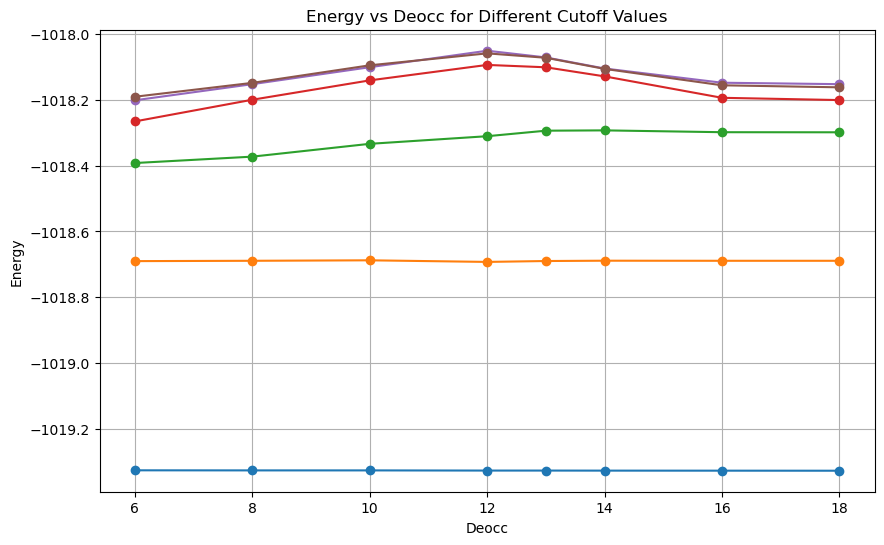

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming your data is in a CSV file, read it into a DataFrame
# If the data is in another format, adjust the reading method as needed
columns = ["Cutoff", "Deocc", "Pair Strength", "Energy", "epairn", "RMSC", "RMSN", "N_boundn"]
data = pd.read_csv("summary_1.txt", sep='\\s+', skiprows=3, names=columns)
print(data.head())

# Plot Energy vs Deocc for each unique Cutoff
plt.figure(figsize=(10, 6))

# Group data by the 'Cutoff' column
for cutoff, group in data.groupby("Cutoff"):
    # Plot each group separately
    plt.plot(group["Deocc"], group["Energy"], label=f"Cutoff {cutoff}", marker="o")

# Label the axes and add a legend
plt.xlabel("Deocc")
plt.ylabel("Energy")
plt.title("Energy vs Deocc for Different Cutoff Values")
# plt.legend()
plt.grid(True)
plt.show()


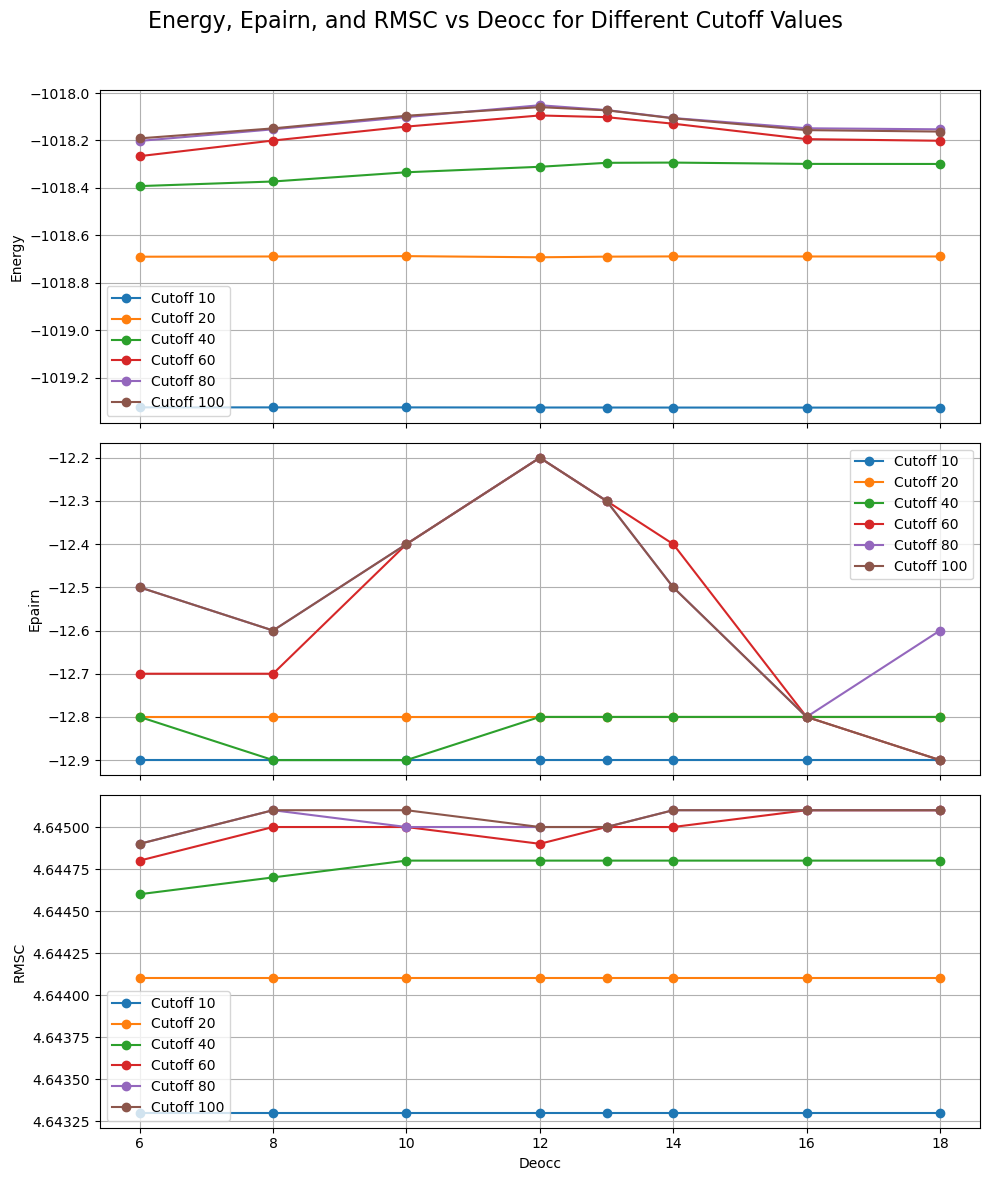

In [21]:
import matplotlib.cm as cm

# Set up a 3-row, 1-column panel plot
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)
fig.suptitle("Energy, Epairn, and RMSC vs Deocc for Different Cutoff Values", fontsize=16)

# Define the columns to plot and their respective y-axis labels
plot_columns = [("Energy", "Energy"), ("epairn", "Epairn"), ("RMSC", "RMSC")]

# Generate unique colors for each Cutoff value
cutoff_values = sorted(data["Cutoff"].unique())
colors = cm.viridis(np.linspace(0, 1, len(cutoff_values)))  # Using the viridis colormap

# Create a color dictionary mapping each Cutoff to a color
color_dict = {cutoff: color for cutoff, color in zip(cutoff_values, colors)}

# Loop over each column to create a subplot
for ax, (col, ylabel) in zip(axes, plot_columns):
    # Group by 'Cutoff' and plot each group on the current subplot
    for cutoff, group in data.groupby("Cutoff"):
        ax.plot(group["Deocc"], group[col], label=f"Cutoff {cutoff}", marker="o")
    
    # Set y-axis label for each subplot
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True)

# Set the x-axis label for the last subplot
axes[-1].set_xlabel("Deocc")

# Adjust layout for better spacing between plots
plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust to make room for the main title
plt.savefig('summary_hfb_1.png')